   # Lab 01 : Data Preparation, Model Training, and Evaluation for Cybersecurity AI

# 1. Data Preparation 

## 1.1 Loading

In [4]:
import pandas as pd  #py tool works with tables like excel

train = pd.read_csv("UNSW_NB15_training-set.csv")
test = pd.read_csv("UNSW_NB15_testing-set.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (175341, 45)
Test: (82332, 45)


## 1.2 Exploring the training dataset

In [5]:
print("Shape:", train.shape)

print("\nData types:")
print(train.dtypes.value_counts())

print("\nMissing values:", train.isna().sum().sum())

print("\nlabel distribution:")
print(train["label"].value_counts())

print("Attack category distribution: ")
print(train["attack_cat"].value_counts())

Shape: (175341, 45)

Data types:
int64      30
float64    11
str         4
Name: count, dtype: int64

Missing values: 0

label distribution:
label
1    119341
0     56000
Name: count, dtype: int64
Attack category distribution: 
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


## 1.3: Clean the data

In [6]:
import numpy as np #loads a tool that works with numbers

# we check infinite values
print("Inf in train:", np.isinf(train.select_dtypes("number")).sum().sum())
print("Inf in test:", np.isinf(test.select_dtypes("number")).sum().sum())

#we get rid of the id column
train = train.drop(columns=["id"])
test = test.drop(columns=["id"])

#we replace inf values by NaN
train = train.replace([np.inf, -np.inf], np.nan)
test = test.replace([np.inf, -np.inf], np.nan)

print("\nMissing in train:", train.isna().sum().sum())
print("Missing in test:", test.isna().sum().sum())
print("Final shapes:", train.shape, test.shape)

Inf in train: 0
Inf in test: 0

Missing in train: 0
Missing in test: 0
Final shapes: (175341, 44) (82332, 44)


## 1.4 Encoding

In [7]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["proto", "service", "state"]

num_cols = [
    c for c in train.columns 
    if c not in cat_cols + ["attack_cat", "label"]
]

for c in cat_cols:
    only_in_test = set(test[c]) - set(train[c])
    print(c, "| values in train:", train[c].nunique(), "| only in test:", only_in_test)

encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(train[cat_cols])

print("Text columns:", len(cat_cols))
print("Number columns:", len(num_cols))
print("Columns after encoding:", len(encoder.get_feature_names_out()))

proto | values in train: 133 | only in test: set()
service | values in train: 13 | only in test: set()
state | values in train: 9 | only in test: {'ACC', 'CLO'}
Text columns: 3
Number columns: 39
Columns after encoding: 155


## 1.5 scaling

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(train[num_cols])

train_scaled = pd.DataFrame(scaler.transform(train[num_cols]), columns=num_cols)
test_scaled = pd.DataFrame(scaler.transform(test[num_cols]), columns=num_cols)

print("sbytes before:", train["sbytes"].min(), "to", train["sbytes"].max())
print("sbytes after (train): mean =", round(train_scaled["sbytes"].mean(), 3), "| std =", round(train_scaled["sbytes"].std(), 3))
print("sbytes after (test) : mean =", round(test_scaled["sbytes"].mean(), 3), "| std =", round(test_scaled["sbytes"].std(), 3))

sbytes before: 28 to 12965233
sbytes after (train): mean = -0.0 | std = 1.0
sbytes after (test) : mean = -0.005 | std = 0.982


## 1.6 feature_selection

In [9]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(f_classif, k=10)
selector.fit(train[num_cols], train["label"])

scores = pd.Series(selector.scores_, index=num_cols).sort_values(ascending=False)

print("Top 10 columns:")
print(scores.head(10).round(1))
print()
print("Weakest 5 columns:")
print(scores.tail(5).round(1))

Top 10 columns:
sttl                161780.5
ct_state_ttl         87830.8
dload                32170.3
ct_dst_sport_ltm     25646.0
dmean                23195.0
rate                 22611.8
swin                 21961.8
dwin                 19950.9
ct_src_dport_ltm     18059.2
ct_dst_src_ltm       17835.4
dtype: float64

Weakest 5 columns:
is_ftp_login    21.4
trans_depth     20.5
smean           20.4
sjit             8.8
sloss            0.1
dtype: float64


## 1.7 imbalance

attack_cat
Normal            31.94
Generic           22.81
Exploits          19.04
Fuzzers           10.37
DoS                6.99
Reconnaissance     5.98
Analysis           1.14
Backdoor           1.00
Shellcode          0.65
Worms              0.07
Name: count, dtype: float64

Biggest class: Normal 56000
Smallest class: Worms 130
Biggest / smallest = 430.8

label
1    68.06
0    31.94
Name: proportion, dtype: float64


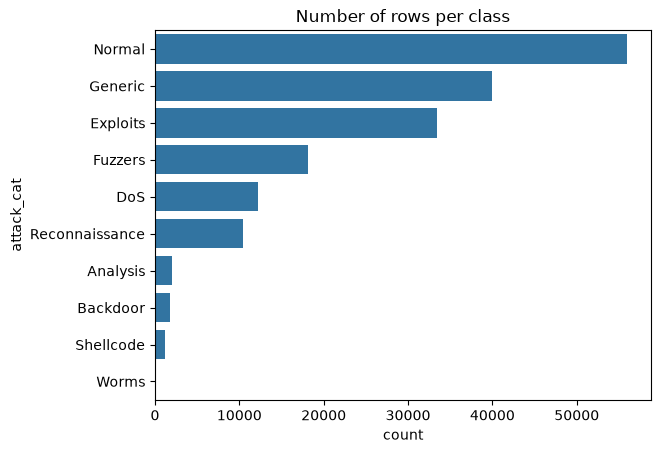

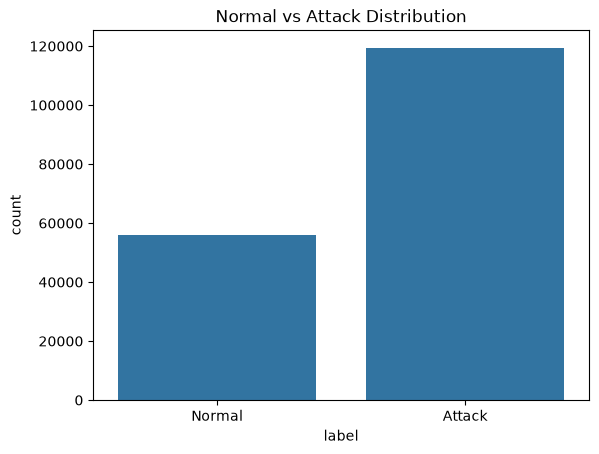

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

counts = train["attack_cat"].value_counts()

print((counts / len(train) * 100).round(2))
print()
print("Biggest class:", counts.idxmax(), counts.max())
print("Smallest class:", counts.idxmin(), counts.min())
print("Biggest / smallest =", round(counts.max() / counts.min(), 1))
print()
print((train["label"].value_counts(normalize=True) * 100).round(2))

sns.countplot(y="attack_cat", data=train, order=counts.index)
plt.title("Number of rows per class")
plt.show()

sns.countplot(x="label", data=train)
plt.title("Normal vs Attack Distribution")
plt.xticks([0, 1], ["Normal", "Attack"])
plt.show()

## 1.8 split

In [11]:
from sklearn.model_selection import train_test_split

RS = 42

X = train.drop(columns=["attack_cat", "label"])
y_multi = train["attack_cat"]
y_bin = train["label"]

Xtr, Xval, ymtr, ymval, ybtr, ybval = train_test_split(
    X, y_multi, y_bin, test_size=0.2, stratify=y_multi, random_state=RS)

X_test = test.drop(columns=["attack_cat", "label"])

print("Training part:", Xtr.shape)
print("Validation part:", Xval.shape)
print("Test:", X_test.shape)
print()
print(pd.DataFrame({"train %": ymtr.value_counts(normalize=True) * 100,
                    "validation %": ymval.value_counts(normalize=True) * 100}).round(2))

Training part: (140272, 42)
Validation part: (35069, 42)
Test: (82332, 42)

                train %  validation %
attack_cat                           
Normal            31.94         31.94
Generic           22.81         22.81
Exploits          19.04         19.05
Fuzzers           10.37         10.37
DoS                6.99          6.99
Reconnaissance     5.98          5.98
Analysis           1.14          1.14
Backdoor           1.00          1.00
Shellcode          0.65          0.65
Worms              0.07          0.07


# 2. Model Training & Classification strategies

## 2.1: Training the two models

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_pipe(model):
    prep = ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

lr = make_pipe(LogisticRegression(max_iter=1000, random_state=RS))
rf = make_pipe(RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=-1))

lr.fit(Xtr, ymtr)
rf.fit(Xtr, ymtr)

print("Logistic Regression - validation accuracy:", round(lr.score(Xval, ymval), 4))
print("Random Forest       - validation accuracy:", round(rf.score(Xval, ymval), 4))

Logistic Regression - validation accuracy: 0.7772
Random Forest       - validation accuracy: 0.8232


## 2.2 search

In [13]:
from sklearn.metrics import f1_score

best_score = -1
for C in [0.1, 1, 10]:
    pipe = make_pipe(LogisticRegression(C=C, max_iter=1000, random_state=RS))
    pipe.fit(Xtr, ymtr)
    score = f1_score(ymval, pipe.predict(Xval), average="macro")
    print("Logistic Regression | C =", C, "| validation macro F1 =", round(score, 4))
    if score > best_score:
        best_score = score
        best_lr = pipe
        best_C = C

best_score = -1
for depth in [10, 20, None]:
    pipe = make_pipe(RandomForestClassifier(max_depth=depth, n_estimators=100, random_state=RS, n_jobs=-1))
    pipe.fit(Xtr, ymtr)
    score = f1_score(ymval, pipe.predict(Xval), average="macro")
    print("Random Forest | max_depth =", depth, "| validation macro F1 =", round(score, 4))
    if score > best_score:
        best_score = score
        best_rf = pipe
        best_depth = depth

print()
print("Best C for Logistic Regression:", best_C)
print("Best max_depth for Random Forest:", best_depth)

Logistic Regression | C = 0.1 | validation macro F1 = 0.4033
Logistic Regression | C = 1 | validation macro F1 = 0.4134
Logistic Regression | C = 10 | validation macro F1 = 0.4264
Random Forest | max_depth = 10 | validation macro F1 = 0.4184
Random Forest | max_depth = 20 | validation macro F1 = 0.5695
Random Forest | max_depth = None | validation macro F1 = 0.575

Best C for Logistic Regression: 10
Best max_depth for Random Forest: None


## 2.3: Training vs validation

In [14]:
from sklearn.metrics import accuracy_score, f1_score

for name, pipe in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    for part, X_, y_ in [("Train", Xtr, ymtr), ("Validation", Xval, ymval)]:
        pred = pipe.predict(X_)
        print(name, "|", part, "| accuracy =", round(accuracy_score(y_, pred), 4),
              "| macro F1 =", round(f1_score(y_, pred, average="macro"), 4))

Logistic Regression | Train | accuracy = 0.7787 | macro F1 = 0.4238
Logistic Regression | Validation | accuracy = 0.7781 | macro F1 = 0.4264
Random Forest | Train | accuracy = 0.9101 | macro F1 = 0.8007
Random Forest | Validation | accuracy = 0.8232 | macro F1 = 0.575


## 2.4 pipeline

In [15]:
print("Steps in the pipeline:", list(best_rf.named_steps))

scaler = best_rf.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
i = num_cols.index("sbytes")

print("Average learned by the pipeline's scaler:", round(scaler.mean_[i], 2))
print("Average of sbytes in the training part  :", round(Xtr["sbytes"].mean(), 2))
print("Average of sbytes in the validation part:", round(Xval["sbytes"].mean(), 2))

Steps in the pipeline: ['prep', 'model']
Average learned by the pipeline's scaler: 8716.44
Average of sbytes in the training part  : 8716.44
Average of sbytes in the validation part: 9358.43


### Experiment 1: multi-class classification

In [16]:
from sklearn.metrics import classification_report

y_test_multi = test["attack_cat"]

for name, pipe in [("Logistic Regression", best_lr), ("   Random Forest   ", best_rf)]:
    print("=================", name, "==================")
    print(classification_report(y_test_multi, pipe.predict(X_test), zero_division=0))

================= Logistic Regression ==================
                precision    recall  f1-score   support

      Analysis       0.05      0.04      0.05       677
      Backdoor       0.00      0.00      0.00       583
           DoS       0.26      0.02      0.05      4089
      Exploits       0.54      0.79      0.64     11132
       Fuzzers       0.26      0.72      0.39      6062
       Generic       0.99      0.96      0.98     18871
        Normal       0.95      0.64      0.76     37000
Reconnaissance       0.47      0.70      0.56      3496
     Shellcode       0.00      0.00      0.00       378
         Worms       0.14      0.02      0.04        44

      accuracy                           0.70     82332
     macro avg       0.37      0.39      0.35     82332
  weighted avg       0.78      0.70      0.71     82332

=================    Random Forest    ==================
                precision    recall  f1-score   support

      Analysis       0.01      0.01      0

#### Confusion matrix

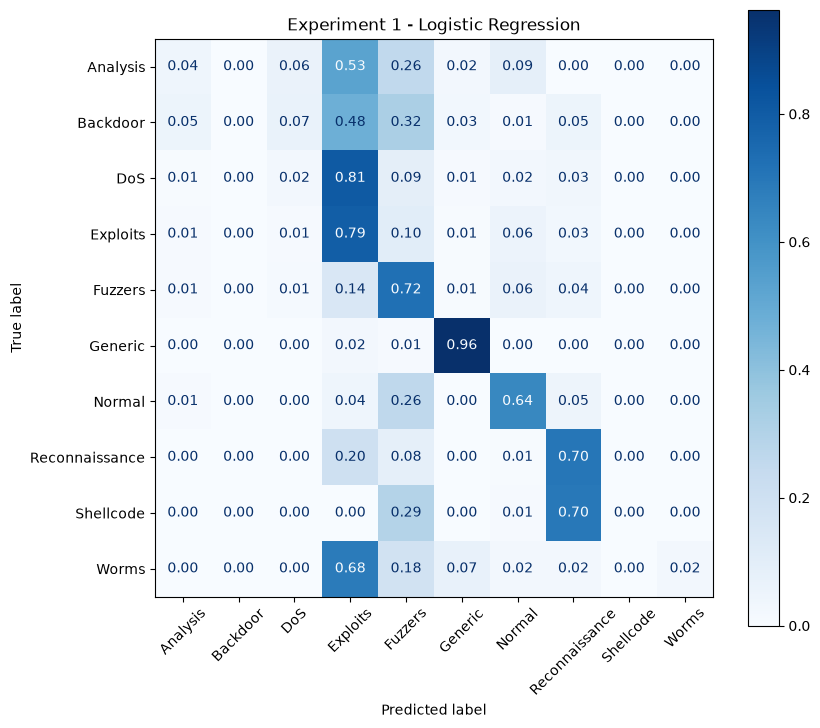

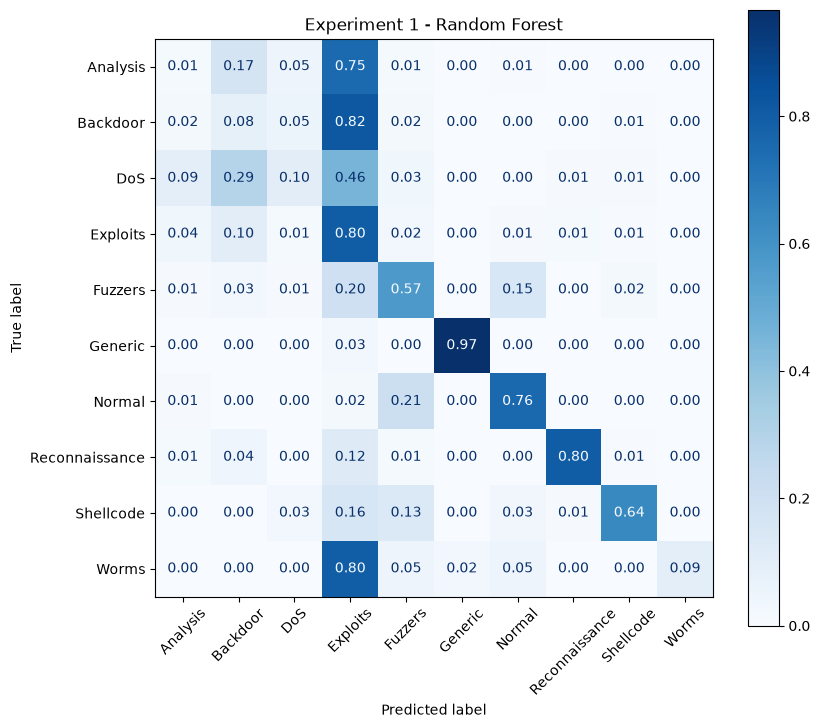

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, pipe in [("Logistic Regression", best_lr), ("Random Forest", best_rf)]:
    fig, ax = plt.subplots(figsize=(9, 8))
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test_multi, normalize="true",
                                          values_format=".2f", xticks_rotation=45,
                                          cmap="Blues", ax=ax)
    ax.set_title("Experiment 1 - " + name)
    plt.show()

#### Comparison table

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def scores(name, pipe, X, y):
    pred = pipe.predict(X)
    proba = pipe.predict_proba(X)
    if len(pipe.classes_) == 2:
        auc = roc_auc_score(y, proba[:, 1])
    else:
        auc = roc_auc_score(y, proba, multi_class="ovr", average="macro")
    return {"Model": name,
            "Accuracy": accuracy_score(y, pred),
            "Precision macro": precision_score(y, pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
            "F1 macro": f1_score(y, pred, average="macro", zero_division=0),
            "Precision weighted": precision_score(y, pred, average="weighted", zero_division=0),
            "Recall weighted": recall_score(y, pred, average="weighted", zero_division=0),
            "F1 weighted": f1_score(y, pred, average="weighted", zero_division=0),
            "ROC-AUC": auc}

table1 = pd.DataFrame([scores("Logistic Regression", best_lr, X_test, y_test_multi),
                       scores("Random Forest", best_rf, X_test, y_test_multi)])
display(table1.round(4))

,Model,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,ROC-AUC
0,Logistic Regression,0.6996,0.3671,0.3909,0.3464,0.7801,0.6996,0.7091,0.9499
1,Random Forest,0.7547,0.5093,0.4820,0.4597,0.8335,0.7547,0.7754,0.9410


### Experiment 2: Normal vs Attack

In [19]:
y_test_bin = test["label"]

best_score = -1
for C in [0.1, 1, 10]:
    pipe = make_pipe(LogisticRegression(C=C, max_iter=1000, random_state=RS))
    pipe.fit(Xtr, ybtr)
    score = f1_score(ybval, pipe.predict(Xval), average="macro")
    print("Logistic Regression | C =", C, "| validation macro F1 =", round(score, 4))
    if score > best_score:
        best_score = score
        best_lr2 = pipe

best_score = -1
for depth in [10, 20, None]:
    pipe = make_pipe(RandomForestClassifier(max_depth=depth, n_estimators=100, random_state=RS, n_jobs=-1))
    pipe.fit(Xtr, ybtr)
    score = f1_score(ybval, pipe.predict(Xval), average="macro")
    print("Random Forest | max_depth =", depth, "| validation macro F1 =", round(score, 4))
    if score > best_score:
        best_score = score
        best_rf2 = pipe

print()
print("Best Logistic Regression:", best_lr2.named_steps["model"])
print("Best Random Forest:", best_rf2.named_steps["model"])

table2 = pd.DataFrame([scores("Logistic Regression", best_lr2, X_test, y_test_bin),
                       scores("Random Forest", best_rf2, X_test, y_test_bin)])
display(table2.round(4))

Logistic Regression | C = 0.1 | validation macro F1 = 0.9221
Logistic Regression | C = 1 | validation macro F1 = 0.9237
Logistic Regression | C = 10 | validation macro F1 = 0.9242
Random Forest | max_depth = 10 | validation macro F1 = 0.9272
Random Forest | max_depth = 20 | validation macro F1 = 0.9519
Random Forest | max_depth = None | validation macro F1 = 0.9528

Best Logistic Regression: LogisticRegression(C=10, max_iter=1000, random_state=42)
Best Random Forest: RandomForestClassifier(n_jobs=-1, random_state=42)


,Model,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,ROC-AUC
0,Logistic Regression,0.8107,0.8511,0.7925,0.7970,0.8413,0.8107,0.8023,0.9563
1,Random Forest,0.8720,0.8980,0.8591,0.8658,0.8900,0.8720,0.8687,0.9789


#### Confusion matrix and ROC curve

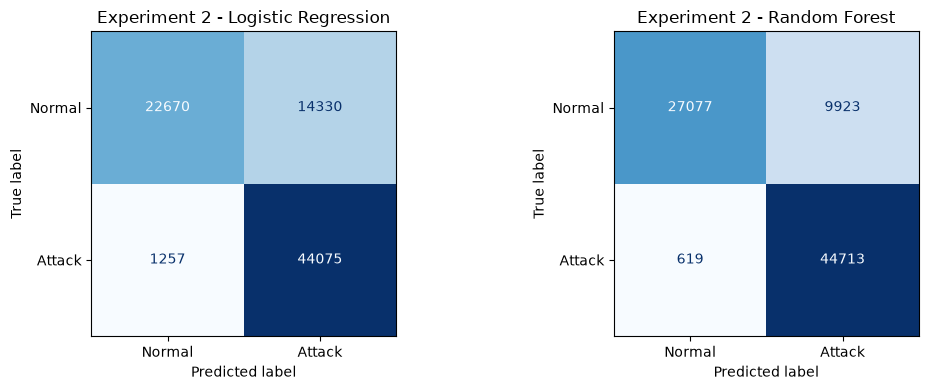

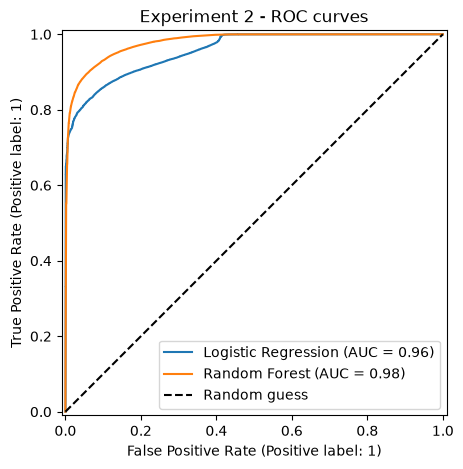

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pipe) in zip(axes, [("Logistic Regression", best_lr2), ("Random Forest", best_rf2)]):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test_bin, display_labels=["Normal", "Attack"],
                                          values_format="d", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title("Experiment 2 - " + name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in [("Logistic Regression", best_lr2), ("Random Forest", best_rf2)]:
    RocCurveDisplay.from_estimator(pipe, X_test, y_test_bin, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
ax.set_title("Experiment 2 - ROC curves")
plt.show()

### Experiment 3 : Binary classification between two selected classes + class imbalance

#### 3.1 Choose two classes and create the subset

In [21]:
two = ["Normal", "Backdoor"]

def subset(X, y):
    keep = y.isin(two)
    return X[keep], (y[keep] == "Backdoor").astype(int)

X3tr, y3tr = subset(Xtr, ymtr)
X3val, y3val = subset(Xval, ymval)
X3te, y3te = subset(X_test, y_test_multi)

print("Training:", y3tr.value_counts().to_dict())
print("Validation:", y3val.value_counts().to_dict())
print("Test:", y3te.value_counts().to_dict())
print("Normal / Backdoor ratio in training:", round(y3tr.value_counts()[0] / y3tr.value_counts()[1], 1))
print("Normal / Backdoor ratio in test:", round(y3te.value_counts()[0] / y3te.value_counts()[1], 1))

Training: {0: 44800, 1: 1397}
Validation: {0: 11200, 1: 349}
Test: {0: 37000, 1: 583}
Normal / Backdoor ratio in training: 32.1
Normal / Backdoor ratio in test: 63.5


#### 3.2 Train without and with imbalance handling

In [23]:
from sklearn.metrics import precision_score, recall_score

models = {
    "Logistic Regression (no balancing)": make_pipe(LogisticRegression(C=10, max_iter=1000, random_state=RS)),
    "Logistic Regression (balanced)": make_pipe(LogisticRegression(C=10, max_iter=1000, class_weight="balanced", random_state=RS)),
    "Random Forest (no balancing)": make_pipe(RandomForestClassifier(n_estimators=100, random_state=RS, n_jobs=-1)),
    "Random Forest (balanced)": make_pipe(RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RS, n_jobs=-1)),
}

rows = []
for name, pipe in models.items():
    pipe.fit(X3tr, y3tr)
    row = scores(name, pipe, X3te, y3te)
    pred = pipe.predict(X3te)
    row["Backdoor precision"] = precision_score(y3te, pred, zero_division=0)
    row["Backdoor recall"] = recall_score(y3te, pred)
    rows.append(row)

table3 = pd.DataFrame(rows)
display(table3.round(4))

,Model,Accuracy,Precision macro,Recall macro,F1 macro,Precision weighted,Recall weighted,F1 weighted,ROC-AUC,Backdoor precision,Backdoor recall
0,Logistic Regression (no balancing),0.9972,0.9859,0.9209,0.9510,0.9972,0.9972,0.9971,0.9919,0.9742,0.8422
1,Logistic Regression (balanced),0.9193,0.5776,0.9354,0.6126,0.9861,0.9193,0.9466,0.9909,0.1559,0.9520
2,Random Forest (no balancing),0.9992,0.9894,0.9853,0.9873,0.9992,0.9992,0.9992,0.9995,0.9792,0.9708
3,Random Forest (balanced),0.9986,0.9743,0.9807,0.9775,0.9986,0.9986,0.9986,0.9995,0.9492,0.9623


#### 3.3 Confusion matrices

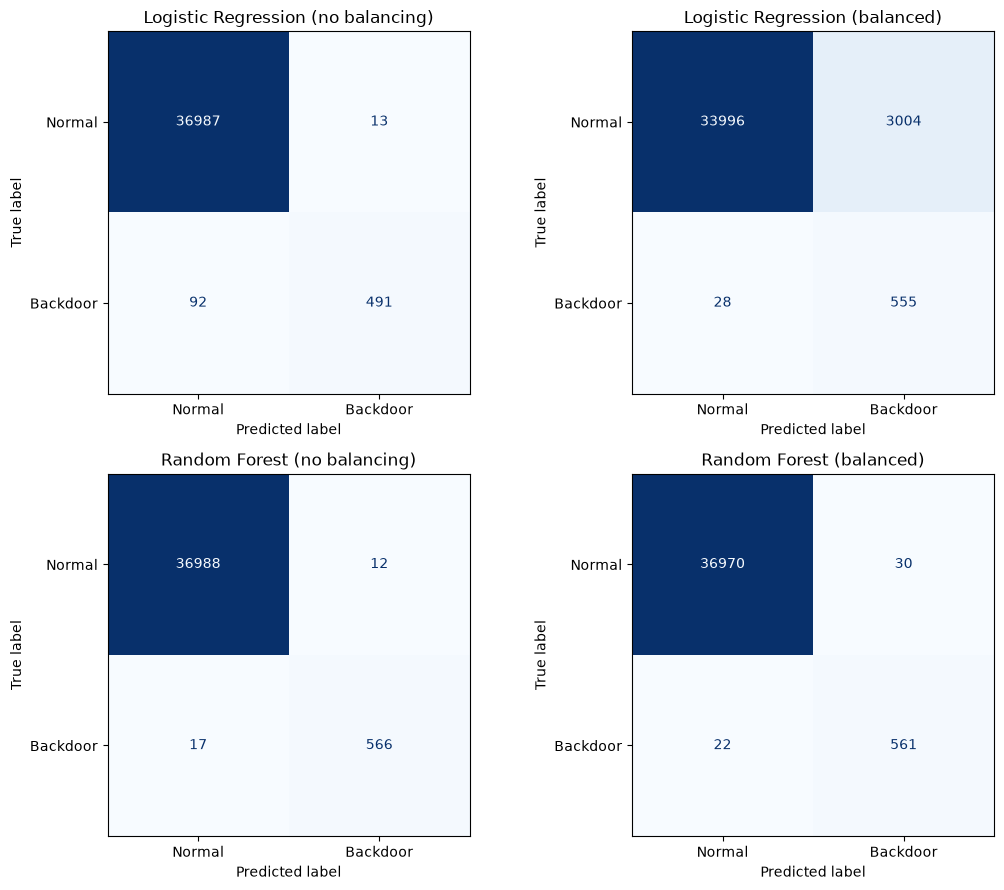

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, pipe) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X3te, y3te, display_labels=["Normal", "Backdoor"],
                                          values_format="d", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# The final comparison table

In [25]:
table1["Experiment"] = "Exp 1 - Multi-class"
table2["Experiment"] = "Exp 2 - Normal vs Attack"
table3["Experiment"] = "Exp 3 - Normal vs Backdoor"

final = pd.concat([table1, table2, table3], ignore_index=True)
final = final[["Experiment", "Model", "Accuracy", "Precision macro", "Recall macro", "F1 macro", "F1 weighted", "ROC-AUC"]]

display(final.round(4))
final.round(4).to_csv("lab01_final_results.csv", index=False)

,Experiment,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,ROC-AUC
0,Exp 1 - Multi-class,Logistic Regression,0.6996,0.3671,0.3909,0.3464,0.7091,0.9499
1,Exp 1 - Multi-class,Random Forest,0.7547,0.5093,0.4820,0.4597,0.7754,0.9410
2,Exp 2 - Normal vs Attack,Logistic Regression,0.8107,0.8511,0.7925,0.7970,0.8023,0.9563
3,Exp 2 - Normal vs Attack,Random Forest,0.8720,0.8980,0.8591,0.8658,0.8687,0.9789
4,Exp 3 - Normal vs Backdoor,Logistic Regression (no balancing),0.9972,0.9859,0.9209,0.9510,0.9971,0.9919
5,Exp 3 - Normal vs Backdoor,Logistic Regression (balanced),0.9193,0.5776,0.9354,0.6126,0.9466,0.9909
6,Exp 3 - Normal vs Backdoor,Random Forest (no balancing),0.9992,0.9894,0.9853,0.9873,0.9992,0.9995
7,Exp 3 - Normal vs Backdoor,Random Forest (balanced),0.9986,0.9743,0.9807,0.9775,0.9986,0.9995
